## Objectives

To train logistic regression, we need a cost function $J(\mathbf w, b)$ that measures how well the model fits the training labels. In this lab you will

- see why the squared-error cost of linear regression is a bad choice here;
- implement the logistic loss and the logistic cost, and understand why they punish confident mistakes;
- see where the logistic loss comes from (maximum likelihood, optional);
- compute the cost without taking the logarithm of zero.

Lab 9 then minimises this cost with gradient descent.

## Tools

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

np.set_printoptions(precision=3, suppress=True)   # print arrays with 3 decimals, no e-notation

def sigmoid(z):
    """Sigmoid function g(z) = 1 / (1 + exp(-z)), element by element (Lab 7)."""
    return 1.0 / (1.0 + np.exp(-z))

## The training set

We use a small data set from the lecture: ten tumours with one feature $x$ and labels $y \in \{0, 1\}$. Unlike the tumour data of Lab 7, the two classes overlap: no single point separates them.

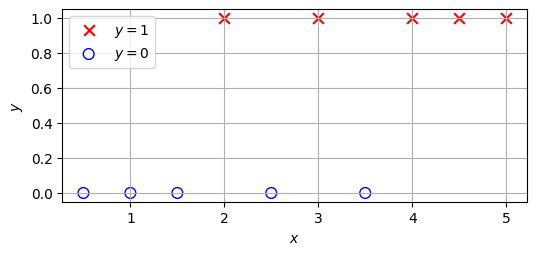

In [2]:
x_train = np.array([0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0])
y_train = np.array([0, 0, 0, 1, 0, 1, 0, 1, 1, 1])

plt.figure(figsize=(6, 2.5))
plt.scatter(x_train[y_train == 1], y_train[y_train == 1], marker='x', c='r', s=60, label='$y = 1$')
plt.scatter(x_train[y_train == 0], y_train[y_train == 0], marker='o', facecolor='none',
            edgecolor='b', s=60, label='$y = 0$')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.legend()
plt.grid(True)
plt.show()

The model is $f_{w,b}(x) = g(wx + b)$, and we want the parameters $(w, b)$ that make $f_{w,b}(x^{(i)})$ close to $y^{(i)}$ for all examples.

## Why not the squared error?

In Lecture 2 we used the average of the per-example **losses** $L = \frac12\big(f_{w,b}(x^{(i)}) - y^{(i)}\big)^2$. For a linear model, this cost is a convex bowl. With the sigmoid inside $f_{w,b}$, it is not. We evaluate it on a grid of $(w, b)$ values:

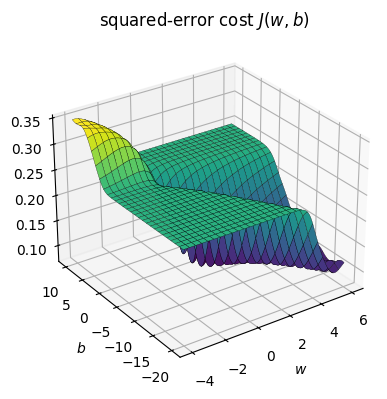

In [3]:
W, B = np.meshgrid(np.linspace(-4, 6, 141), np.linspace(-20, 10, 141))
Z = W[..., None] * x_train + B[..., None]    # shape (141, 141, 10): z for every (w, b) and every example
J_sq = np.mean(0.5 * (sigmoid(Z) - y_train) ** 2, axis=-1)

def plot_surface(J, title, view):
    ax = plt.figure(figsize=(6, 4.5)).add_subplot(projection='3d')
    ax.plot_surface(W, B, J, cmap='viridis', rstride=5, cstride=5, edgecolor='k', lw=0.2)
    ax.view_init(28, view)
    ax.set(xlabel='$w$', ylabel='$b$', title=title + ' $J(w, b)$')
    plt.show()

plot_surface(J_sq, 'squared-error cost', view=-125)

`W[..., None]` adds a new last axis, so that broadcasting combines every grid point $(w, b)$ with every example $x^{(i)}$; the mean over the last axis then averages over the examples. This replaces a double loop over the grid.

The surface has large **flat plateaus**. There the sigmoid is saturated, i.e. it is almost $0$ or $1$ for all examples and hardly changes with $(w, b)$. The gradient is then almost zero and gradient descent stalls. A cost of this shape can also have local minima. We need a better cost.

## The logistic loss

For one example with prediction $f = f_{\mathbf w,b}(\mathbf x)$ and label $y$, the **logistic loss** is
$$
L(f, y) = \begin{cases} -\log(f) & \text{if } y = 1,\\ -\log(1 - f) & \text{if } y = 0.\end{cases}
$$

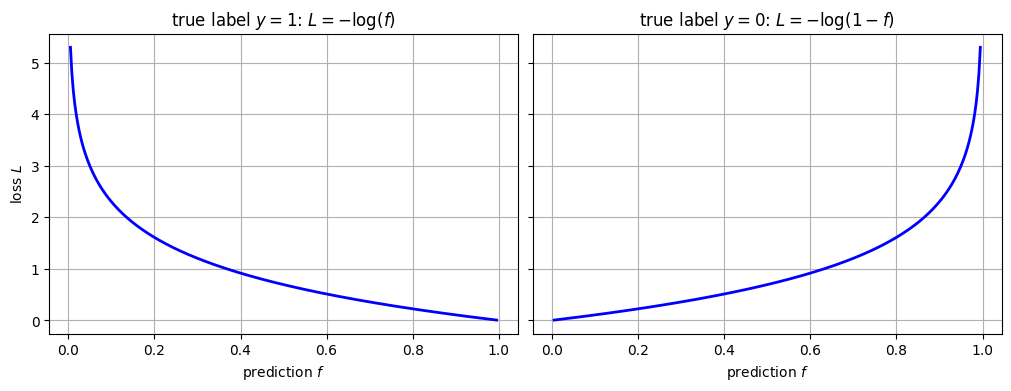

In [4]:
f = np.linspace(0.005, 0.995, 300)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True, constrained_layout=True)
ax[0].plot(f, -np.log(f), 'b-', lw=2)
ax[0].set(xlabel='prediction $f$', ylabel='loss $L$', title='true label $y = 1$: $L = -\\log(f)$')
ax[1].plot(f, -np.log(1 - f), 'b-', lw=2)
ax[1].set(xlabel='prediction $f$', title='true label $y = 0$: $L = -\\log(1 - f)$')
for a in ax:
    a.grid(True)
plt.show()

The loss is $0$ when the model predicts the true label with full confidence, and it grows without bound when the model is confident **and wrong**: confident mistakes are punished severely.

### A single formula

Because $y$ is either $0$ or $1$, both cases fit into one expression:
$$
L(f, y) = -y\log(f) - (1 - y)\log(1 - f).
$$
For $y = 1$ the second term vanishes and $L = -\log(f)$; for $y = 0$ the first term vanishes and $L = -\log(1 - f)$. The cost is the average loss over the training set:
$$
J(\mathbf w, b) = -\frac{1}{m}\sum_{i=1}^{m}\Big[y^{(i)}\log f_{\mathbf w,b}(\mathbf x^{(i)}) + \big(1 - y^{(i)}\big)\log\big(1 - f_{\mathbf w,b}(\mathbf x^{(i)})\big)\Big].
$$
Note the minus sign in front of the sum. Other names for this cost are **log loss** and **binary cross-entropy**.

In [5]:
def logistic_loss(f, y):
    """Logistic loss of predictions f (probabilities) for labels y (0 or 1), element by element."""
    return -y * np.log(f) - (1 - y) * np.log(1 - f)

def compute_cost(x, y, w, b):
    """Logistic cost J(w, b) for one feature x (the lecture's formula)."""
    return np.mean(logistic_loss(sigmoid(w * x + b), y))

for f_i, y_i in [(0.9, 1), (0.5, 1), (0.01, 1), (0.9, 0)]:
    print(f"f = {f_i}, y = {y_i}: L = {logistic_loss(f_i, y_i):.3f}")
print(f"J(0, 0) = {compute_cost(x_train, y_train, 0.0, 0.0):.4f}, log(2) = {np.log(2):.4f}")

f = 0.9, y = 1: L = 0.105
f = 0.5, y = 1: L = 0.693
f = 0.01, y = 1: L = 4.605
f = 0.9, y = 0: L = 2.303
J(0, 0) = 0.6931, log(2) = 0.6931


A correct prediction with $f = 0.9$ costs $0.11$, an undecided $f = 0.5$ costs $\log 2 \approx 0.69$, and a confident mistake ($f = 0.01$ for $y = 1$) costs $4.6$. With $w = 0$ and $b = 0$, every prediction is $g(0) = 0.5$, so $J(0, 0) = \log 2$: a useful check of the code.

### The logistic cost is convex

We now plot the logistic cost on the same grid. (The function `loss_from_z` computes the same loss in a numerically safer way; it is explained at the end of this lab.)

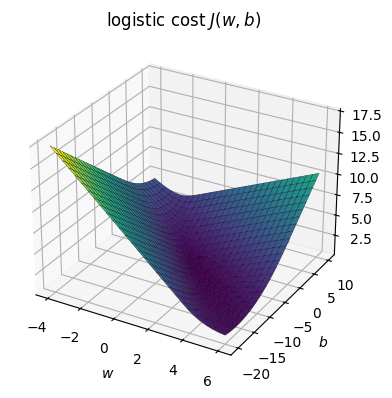

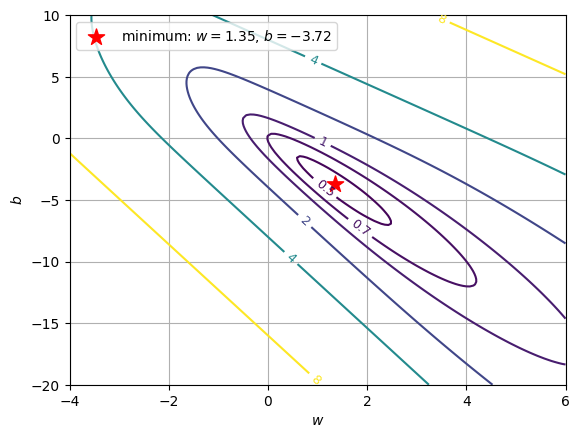

In [6]:
def loss_from_z(z, y):
    """Logistic loss computed from z = w . x + b, without forming log(f) or log(1 - f)."""
    return y * np.logaddexp(0, -z) + (1 - y) * np.logaddexp(0, z)

J_log = np.mean(loss_from_z(Z, y_train), axis=-1)
plot_surface(J_log, 'logistic cost', view=-60)

best = LogisticRegression(C=1e10).fit(x_train.reshape(-1, 1), y_train)   # C=1e10: no regularisation
w_best, b_best = best.coef_[0, 0], best.intercept_[0]
cs = plt.contour(W, B, J_log, levels=[0.4, 0.5, 0.7, 1, 2, 4, 8], cmap='viridis')
plt.clabel(cs, fmt='%g', fontsize=9)
plt.scatter(w_best, b_best, marker='*', c='r', s=150, zorder=3,
            label=f'minimum: $w = {w_best:.2f}$, $b = {b_best:.2f}$')
plt.xlabel('$w$')
plt.ylabel('$b$')
plt.legend()
plt.grid(True)
plt.show()

The logistic cost is **convex**: a single valley without plateaus, with its minimum near $(w, b) = (1.35, -3.72)$. Gradient descent cannot get stuck in it. Here scikit-learn located the minimum; Lab 9 finds the same point with our own gradient descent.

::: {.callout-note collapse="true" title="Where does the logistic loss come from? (optional)"}
The model states $P(y = 1 \mid \mathbf x) = f$ and $P(y = 0 \mid \mathbf x) = 1 - f$, or in one formula $P(y \mid \mathbf x) = f^{\,y}(1 - f)^{1 - y}$. If the training examples are independent, the probability that the model assigns to all observed labels, the **likelihood**, is the product $\prod_{i=1}^{m} P\big(y^{(i)} \mid \mathbf x^{(i)}\big)$. Good parameters make it large. Taking $-\frac1m\log$ turns the product into a sum and maximising into minimising:
$$
-\frac1m\log\prod_{i=1}^{m} P\big(y^{(i)} \mid \mathbf x^{(i)}\big) = -\frac1m\sum_{i=1}^{m}\Big[y^{(i)}\log f^{(i)} + \big(1 - y^{(i)}\big)\log\big(1 - f^{(i)}\big)\Big] = J(\mathbf w, b).
$$
So minimising $J$ is **maximum likelihood estimation**, and each loss is $-\log(\text{probability of the true label})$. A numerical check at the minimum:

In [7]:
f_best = sigmoid(w_best * x_train + b_best)
likelihood = np.prod(f_best ** y_train * (1 - f_best) ** (1 - y_train))
print(f"likelihood = {likelihood:.6f}, exp(-m J) = {np.exp(-len(y_train) * compute_cost(x_train, y_train, w_best, b_best)):.6f}")

likelihood = 0.013100, exp(-m J) = 0.013100


:::

## Computing the cost safely

In exact arithmetic $0 < f < 1$. In floating point, however, $g(z)$ is rounded to exactly $1.0$ once $z$ exceeds about $37$, and then $\log(1 - f) = \log(0) = -\infty$:

In [8]:
z_big = np.array([40.0, 40.0])
y_big = np.array([0, 1])
print(f"sigmoid(40.0) == 1.0: {sigmoid(40.0) == 1.0}")
print(f"losses: {logistic_loss(sigmoid(z_big), y_big)}")      # NumPy warns

sigmoid(40.0) == 1.0: True
losses: [inf nan]


/tmp/ipykernel_1301/2898237542.py:3: RuntimeWarning: divide by zero encountered in log
  return -y * np.log(f) - (1 - y) * np.log(1 - f)
/tmp/ipykernel_1301/2898237542.py:3: RuntimeWarning: invalid value encountered in multiply
  return -y * np.log(f) - (1 - y) * np.log(1 - f)


NumPy prints two `RuntimeWarning`s, and both losses are wrong. For $y = 0$ the true loss is about $40$, not $\infty$. For $y = 1$ the true loss is tiny, but the formula computes $0\cdot\log(0) = 0\cdot(-\infty)$, which is undefined (`nan`). One such example turns the whole cost into `inf` or `nan`. Large values of $z$ are common, e.g. for unscaled features or during training on separable data (Lab 9).

The cure is to compute the loss directly from $z$. Since $-\log g(z) = \log(1 + e^{-z})$ and $-\log\big(1 - g(z)\big) = \log(1 + e^{z})$,
$$
L = y\log\big(1 + e^{-z}\big) + (1 - y)\log\big(1 + e^{z}\big),
$$
and `np.logaddexp(0, t)` computes $\log(e^0 + e^{t}) = \log(1 + e^{t})$ without overflow. This is the function `loss_from_z` used above for the cost surface.

In [9]:
L_big = loss_from_z(z_big, y_big)
print(f"stable losses: {L_big[0]:.1f} and {L_big[1]:.1e}")
print(f"same cost as before at (w, b) = (1, -3): "
      f"{compute_cost(x_train, y_train, 1.0, -3.0):.6f} and {np.mean(loss_from_z(1.0 * x_train - 3.0, y_train)):.6f}")

stable losses: 40.0 and 4.2e-18
same cost as before at (w, b) = (1, -3): 0.450340 and 0.450340


scikit-learn and PyTorch compute the logistic loss in the same way. From now on we use this stable version.

## Challenges

1. Show that $-\log g(z) = \log(1 + e^{-z})$ and $-\log\big(1 - g(z)\big) = \log(1 + e^{z})$.
2. Plot both costs, $J_{\text{sq}}$ and $J_{\log}$, along the line $b = -3$ as functions of $w$ (one-dimensional slices of the two surfaces). Where is the squared-error cost flat?
3. Change the label of the example at $x = 5$ from $1$ to $0$. How do the cost surface and the position of the minimum change?

## Summary

- With the sigmoid inside $f$, the squared-error cost is not convex and has flat plateaus.
- Logistic loss: $L = -y\log(f) - (1 - y)\log(1 - f)$, i.e. $-\log(\text{probability of the true label})$. It is zero for confident correct predictions and unbounded for confident wrong ones.
- The logistic cost $J(\mathbf w, b)$, the average loss, is convex. Minimising it is maximum likelihood estimation.
- Compute the loss from $z$ with `np.logaddexp`, never as $\log(1 - g(z))$ for large $z$.

**Next (Lab 9):** minimising $J$ with gradient descent, and logistic regression with scikit-learn.